In [1]:

import sys
from pathlib import Path
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.model_validation_convergence as validation

importlib.reload(validation)

pd.set_option("display.float_format", "{:,.2f}".format)

print("Project root:", PROJECT_ROOT)
print("Validation module loaded successfully.")


Project root: /Users/shreyagokhale/Desktop/Docs/Documents/Research projects_cybersecurity/novaflow-fair-crq
Validation module loaded successfully.


In [2]:

# Run convergence analysis

sample_sizes = [
    1_000,
    5_000,
    10_000,
    50_000,
    100_000,
    250_000,
]

convergence_df = validation.run_convergence_analysis(
    sample_sizes=sample_sizes,
    seed=20261025,
)

display(
    convergence_df[
        [
            "n_years",
            "aal_usd",
            "var_95_usd",
            "var_99_usd",
            "tvar_95_usd",
            "tvar_99_usd",
        ]
    ].style.format({
        "n_years": "{:,.0f}",
        "aal_usd": "${:,.0f}",
        "var_95_usd": "${:,.0f}",
        "var_99_usd": "${:,.0f}",
        "tvar_95_usd": "${:,.0f}",
        "tvar_99_usd": "${:,.0f}",
    })
)


,n_years,aal_usd,var_95_usd,var_99_usd,tvar_95_usd,tvar_99_usd
0,"1,000","$255,629","$1,731,438","$3,458,078","$2,793,857","$4,350,780"
1,"5,000","$263,920","$1,763,562","$3,555,663","$2,868,505","$4,708,440"
2,"10,000","$267,501","$1,714,516","$3,635,464","$2,991,531","$5,318,568"
3,"50,000","$277,060","$1,743,985","$3,762,369","$3,013,088","$5,262,523"
4,"100,000","$272,725","$1,730,117","$3,793,562","$3,028,009","$5,285,004"
5,"250,000","$275,944","$1,755,830","$3,792,550","$3,033,335","$5,214,113"


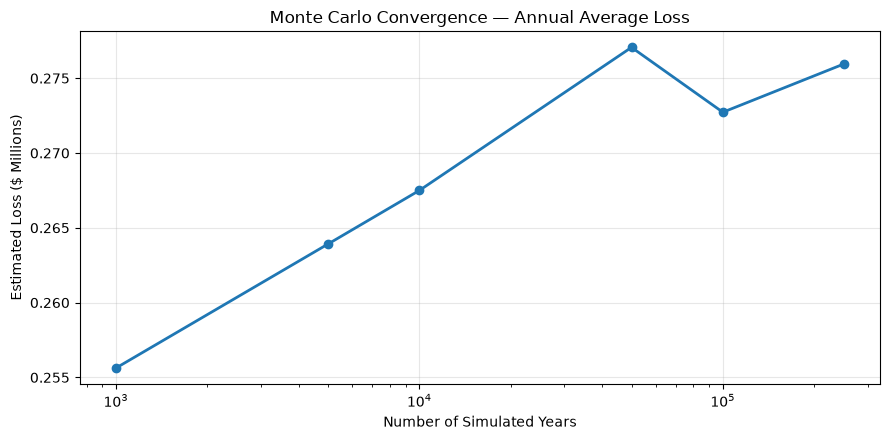

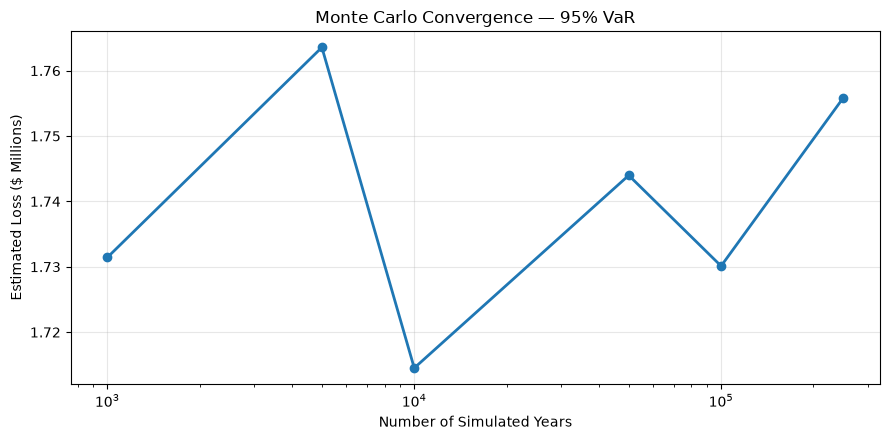

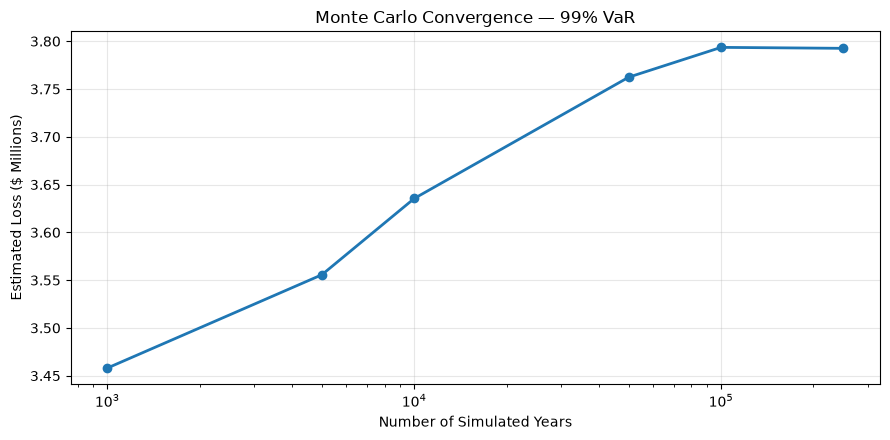

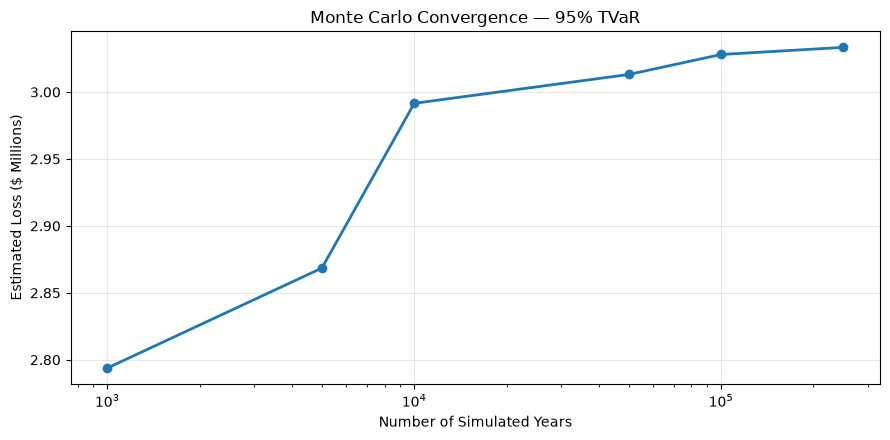

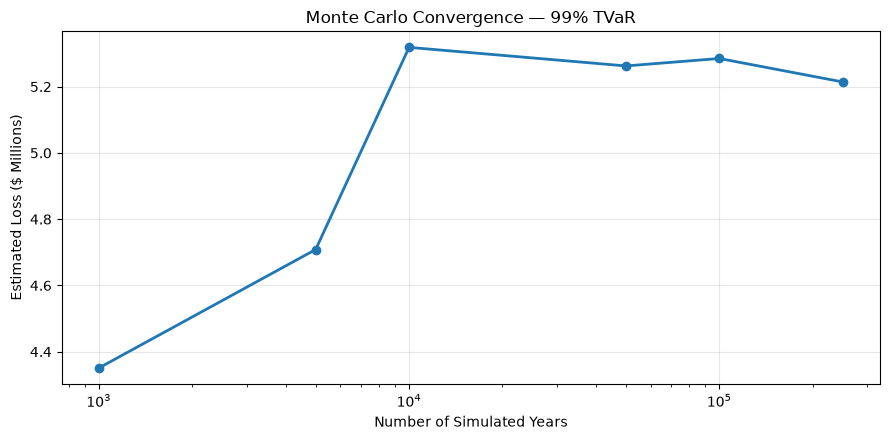

In [3]:
#Plot convergence


metrics_to_plot = {
    "aal_usd": "Annual Average Loss",
    "var_95_usd": "95% VaR",
    "var_99_usd": "99% VaR",
    "tvar_95_usd": "95% TVaR",
    "tvar_99_usd": "99% TVaR",
}

for metric, title in metrics_to_plot.items():

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(
        convergence_df["n_years"],
        convergence_df[metric] / 1_000_000,
        marker="o",
        linewidth=2,
    )

    ax.set_xscale("log")

    ax.set_xlabel("Number of Simulated Years")
    ax.set_ylabel("Estimated Loss ($ Millions)")
    ax.set_title(
        f"Monte Carlo Convergence — {title}"
    )

    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [4]:

#Run independent repetitions

repetitions_df, uncertainty_df = (
    validation.run_repeated_simulations(
        n_years=50_000,
        n_repetitions=20,
        base_seed=20261102,
    )
)

display(
    uncertainty_df.style.format({
        "mean_estimate": "${:,.0f}",
        "sd_across_runs": "${:,.0f}",
        "se_of_mean": "${:,.0f}",
        "relative_sd": "{:.2%}",
        "ci_95_lower": "${:,.0f}",
        "ci_95_upper": "${:,.0f}",
        "min_estimate": "${:,.0f}",
        "max_estimate": "${:,.0f}",
    })
)


,metric,mean_estimate,sd_across_runs,se_of_mean,relative_sd,ci_95_lower,ci_95_upper,min_estimate,max_estimate
0,aal_usd,"$274,616","$2,555",$571,0.93%,"$273,496","$275,735","$270,854","$279,478"
1,var_95_usd,"$1,747,660","$16,322","$3,650",0.93%,"$1,740,506","$1,754,813","$1,714,797","$1,780,393"
2,var_99_usd,"$3,750,379","$65,895","$14,735",1.76%,"$3,721,500","$3,779,259","$3,634,810","$3,889,741"
3,tvar_95_usd,"$3,005,996","$32,551","$7,279",1.08%,"$2,991,730","$3,020,262","$2,935,981","$3,068,284"
4,tvar_99_usd,"$5,156,603","$95,888","$21,441",1.86%,"$5,114,578","$5,198,627","$4,978,867","$5,290,731"


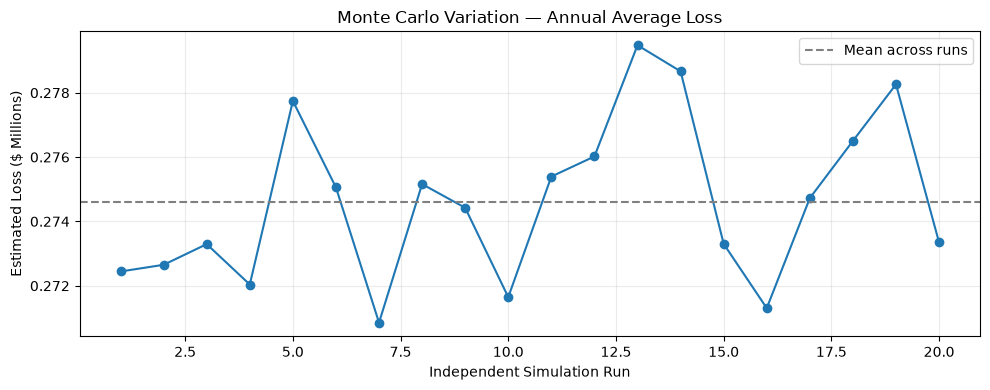

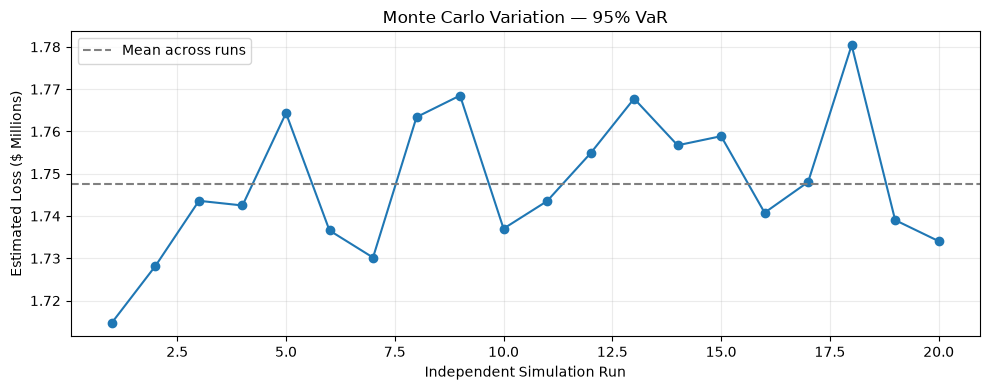

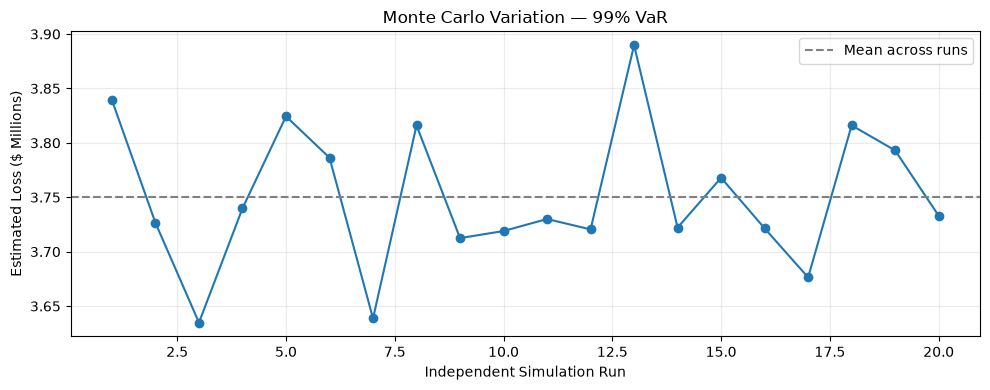

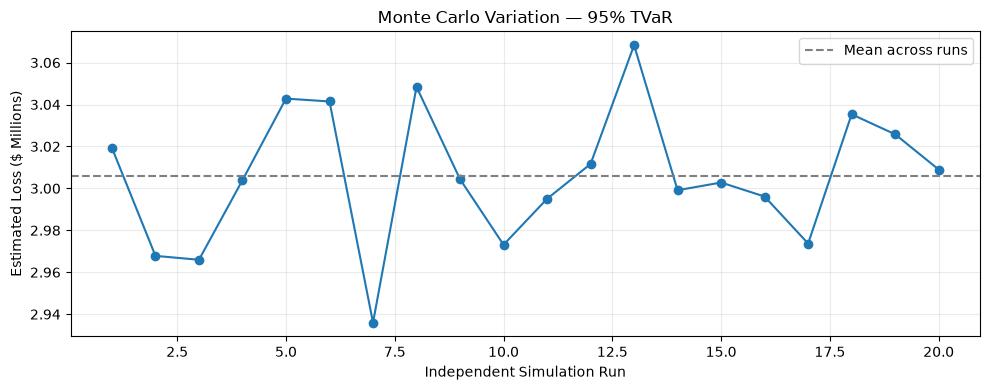

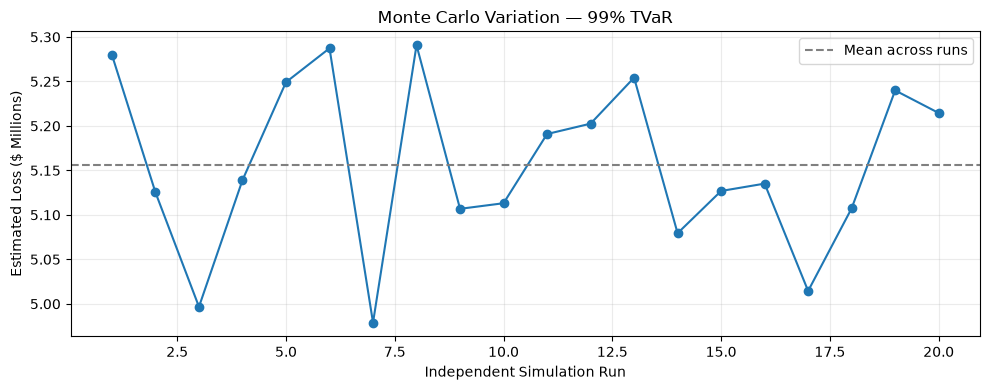

In [5]:
#Visualize variation across independent runs


for metric, title in metrics_to_plot.items():

    fig, ax = plt.subplots(figsize=(10, 4))

    values = (
        repetitions_df[metric].to_numpy()
        / 1_000_000
    )

    ax.plot(
        repetitions_df["repetition"],
        values,
        marker="o",
        linewidth=1.5,
    )

    ax.axhline(
        np.mean(values),
        linestyle="--",
        color="gray",
        label="Mean across runs",
    )

    ax.set_xlabel("Independent Simulation Run")
    ax.set_ylabel("Estimated Loss ($ Millions)")
    ax.set_title(
        f"Monte Carlo Variation — {title}"
    )

    ax.legend()
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


In [6]:
#Compare with our established baseline


baseline_reference = {
    "aal_usd": 272_725.036987,
    "var_95_usd": 1_730_117,
    "var_99_usd": 3_793_562,
    "tvar_95_usd": 3_028_009,
    "tvar_99_usd": 5_285_004,
}

comparison_rows = []

for metric in validation.METRICS:

    reference = baseline_reference[metric]

    row = uncertainty_df.loc[
        uncertainty_df["metric"] == metric
    ].iloc[0]

    mean_estimate = row["mean_estimate"]

    comparison_rows.append({
        "Metric": metric,
        "Original 100K-Year Estimate": reference,
        "Mean Across Independent Runs": mean_estimate,
        "Difference (%)": (
            (mean_estimate / reference - 1) * 100
        ),
        "Relative SD Across Runs (%)": (
            row["relative_sd"] * 100
        ),
    })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        "Original 100K-Year Estimate": "${:,.0f}",
        "Mean Across Independent Runs": "${:,.0f}",
        "Difference (%)": "{:+.2f}%",
        "Relative SD Across Runs (%)": "{:.2f}%",
    })
)


,Metric,Original 100K-Year Estimate,Mean Across Independent Runs,Difference (%),Relative SD Across Runs (%)
0,aal_usd,"$272,725","$274,616",+0.69%,0.93%
1,var_95_usd,"$1,730,117","$1,747,660",+1.01%,0.93%
2,var_99_usd,"$3,793,562","$3,750,379",-1.14%,1.76%
3,tvar_95_usd,"$3,028,009","$3,005,996",-0.73%,1.08%
4,tvar_99_usd,"$5,285,004","$5,156,603",-2.43%,1.86%
